In [1]:
import pandas as pd
import plotly.express as px

# Load your clean data
df = pd.read_csv('data/processed/ukhsa_consumption_clean.csv')

# Melt the data so we can plot two lines easily
df_lines = df.melt(id_vars=['date'], 
                   value_vars=['primary_care_did', 'secondary_care_did'],
                   var_name='Care Setting', 
                   value_name='DID')

# Clean up the legend labels
df_lines['Care Setting'] = df_lines['Care Setting'].map({
    'primary_care_did': 'Primary Care (GP/Community)',
    'secondary_care_did': 'Secondary Care (Hospitals)'
})

# Create the interactive line chart
fig1 = px.line(df_lines, x='date', y='DID', color='Care Setting',
               title='Antibiotic Consumption: Primary vs Secondary Care (2016-2025)',
               labels={'date': 'Date', 'DID': 'Doses per 1,000 inhabitants/day (DID)'},
               color_discrete_map={
                   'Primary Care (GP/Community)': '#1f77b4', 
                   'Secondary Care (Hospitals)': '#ff7f0e'
               })

# Improve the layout
fig1.update_layout(hovermode="x unified")
fig1.show()

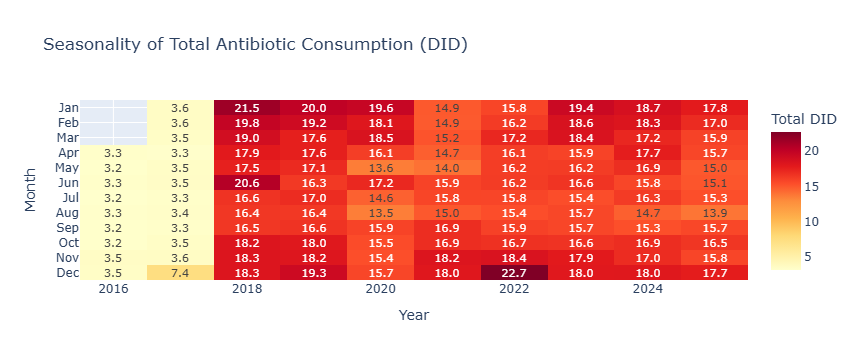

In [2]:
import pandas as pd
import plotly.express as px

# Load your clean data
df = pd.read_csv('data/processed/ukhsa_consumption_clean.csv')

# Ensure date is datetime
df['date'] = pd.to_datetime(df['date'])

# Extract Year and Month for the heatmap
df['Year'] = df['date'].dt.year
df['Month'] = df['date'].dt.strftime('%b') # e.g., 'Jan', 'Feb'

# Define the order of months so they don't sort alphabetically
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Pivot the data for the heatmap
heatmap_data = df.pivot(index='Month', columns='Year', values='total_did')
heatmap_data = heatmap_data.reindex(month_order)

# Create the heatmap
fig2 = px.imshow(heatmap_data, 
                 text_auto=".1f", # Shows the number in the box (1 decimal place)
                 aspect="auto",
                 color_continuous_scale='YlOrRd', # Yellow to Red scale
                 title='Seasonality of Total Antibiotic Consumption (DID)',
                 labels=dict(x="Year", y="Month", color="Total DID"))

fig2.update_layout(xaxis_title="Year", yaxis_title="Month")
fig2.show()